# Lecture Notes: Integration by Parts
*Stewart, **Calculus**, §7.1*

**Learning objectives.** By the end of this lecture you should be able to:
1. Derive the integration by parts formula from the Product Rule.
2. Choose $u$ and $dv$ well (the LIATE heuristic).
3. Handle repeated, cyclic, and definite integrals by parts.
4. Derive and use reduction formulas.
5. Check every answer symbolically with **SymPy** and numerically with **NumPy**.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Math, display

sp.init_printing()
x, n = sp.symbols("x n")

## 1. Where the formula comes from

Every differentiation rule gives an integration rule. The **Substitution Rule** comes from the Chain Rule; **integration by parts** comes from the **Product Rule**:
$$\frac{d}{dx}\big[f(x)\,g(x)\big] = f(x)\,g'(x) + g(x)\,f'(x).$$

Integrate both sides:
$$f(x)\,g(x) = \int f(x)\,g'(x)\,dx + \int g(x)\,f'(x)\,dx,$$

and rearrange:
$$\boxed{\int f(x)\,g'(x)\,dx = f(x)\,g(x) - \int g(x)\,f'(x)\,dx}$$

With $u = f(x)$ and $v = g(x)$, so $du = f'(x)\,dx$ and $dv = g'(x)\,dx$:
$$\boxed{\int u\,dv = uv - \int v\,du}$$

**Definite version** (combine with the Fundamental Theorem of Calculus):
$$\int_a^b f(x)\,g'(x)\,dx = \Big[f(x)\,g(x)\Big]_a^b - \int_a^b g(x)\,f'(x)\,dx$$

**The idea:** swap an integral we can't do, $\int u\,dv$, for one we hopefully can, $\int v\,du$.

Let's check the Product Rule identity with SymPy for general functions $f$ and $g$:

In [2]:
f, g = sp.Function("f")(x), sp.Function("g")(x)

lhs = sp.diff(f * g, x)
rhs = f * sp.diff(g, x) + g * sp.diff(f, x)
print("Product rule holds:", sp.simplify(lhs - rhs) == 0)

Product rule holds: True


## 2. Choosing $u$ and $dv$

There are two requirements:
- $dv$ must be something you can **integrate** to get $v$.
- $\int v\,du$ should be **simpler** than the original integral. Usually that means $u$ gets simpler when differentiated.

**LIATE heuristic:** choose $u$ as the function that appears **first** in this list:

| | Type | Examples |
|---|---|---|
| **L** | Logarithmic | $\ln x$, $\log_2 x$ |
| **I** | Inverse trigonometric | $\tan^{-1}x$, $\sin^{-1}x$ |
| **A** | Algebraic | $x$, $x^2$, $3x^5 - 1$ |
| **T** | Trigonometric | $\sin x$, $\cos 3x$ |
| **E** | Exponential | $e^x$, $2^x$ |

Everything that is left (including $dx$) becomes $dv$.

### A helper function

The function below does **one step** of integration by parts. Given $u$ and $dv$, it returns $uv$ and the new integrand $v\,du$, so we can follow each step the same way we would by hand.

In [3]:
def by_parts(u, dv, var=x, show=True):
    # One step of integration by parts: returns (uv, v*du/dx)
    du = sp.diff(u, var)
    v = sp.integrate(dv, var)  # constant of integration omitted (any v works)
    if show:
        display(Math(
            rf"u = {sp.latex(u)},\quad dv = {sp.latex(dv)}\,d{var}"
            rf"\qquad\Longrightarrow\qquad du = {sp.latex(du)}\,d{var},\quad v = {sp.latex(v)}"
        ))
        display(Math(
            rf"\int {sp.latex(u * dv)}\,d{var} = {sp.latex(u * v)} - \int {sp.latex(sp.simplify(v * du))}\,d{var}"
        ))
    return u * v, sp.simplify(v * du)


def check(F, integrand, var=x):
    # Verify F' = integrand symbolically
    ok = sp.simplify(sp.diff(F, var) - integrand) == 0
    print("d/dx(answer) == integrand:", ok)
    return ok

## 3. Example 1: $\displaystyle\int x\sin x\,dx$

**By hand.** LIATE says Algebraic ($x$) comes before Trig ($\sin x$):
$$u = x,\quad dv = \sin x\,dx \quad\Longrightarrow\quad du = dx,\quad v = -\cos x.$$
$$\int x\sin x\,dx = -x\cos x - \int(-\cos x)\,dx = -x\cos x + \sin x + C.$$

**With SymPy:**

In [4]:
uv, rest = by_parts(x, sp.sin(x))
F = uv - sp.integrate(rest, x)
display(Math(r"\int x\sin x\,dx = " + sp.latex(F) + " + C"))
check(F, x * sp.sin(x));

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


**What if we choose badly?** Take $u = \sin x$ and $dv = x\,dx$. Then $v = x^2/2$ and the new integral $\int \tfrac{x^2}{2}\cos x\,dx$ is *harder*, because the power of $x$ went up.

In [5]:
by_parts(sp.sin(x), x);

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 4. Example 2: $\displaystyle\int \ln x\,dx$ (a single function)

There is only one function here, so take $u = \ln x$ and $dv = dx$:
$$du = \frac{1}{x}\,dx,\qquad v = x.$$
$$\int \ln x\,dx = x\ln x - \int x\cdot\frac{1}{x}\,dx = x\ln x - x + C.$$

The same trick works for $\tan^{-1}x$, $\sin^{-1}x$, and $(\ln x)^2$.

In [6]:
uv, rest = by_parts(sp.log(x), sp.Integer(1))
F = uv - sp.integrate(rest, x)
display(Math(r"\int \ln x\,dx = " + sp.latex(F) + " + C"))
check(F, sp.log(x));

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


## 5. Example 3: $\displaystyle\int x^2 e^x\,dx$ (repeated integration by parts)

Take $u = x^2$ and $dv = e^x\,dx$:
$$\int x^2e^x\,dx = x^2e^x - 2\int xe^x\,dx.$$
The power of $x$ went down by one, so apply parts **again** with $u = x$ and $dv = e^x\,dx$:
$$\int xe^x\,dx = xe^x - e^x + C.$$
Therefore
$$\int x^2e^x\,dx = x^2e^x - 2xe^x + 2e^x + C = e^x(x^2 - 2x + 2) + C.$$

In [7]:
uv1, rest1 = by_parts(x**2, sp.exp(x))
uv2, rest2 = by_parts(x, sp.exp(x))          # rest1 = 2*x*exp(x) -> pull out the 2
F = uv1 - 2 * (uv2 - sp.integrate(rest2, x))
F = sp.factor(F)
display(Math(r"\int x^2 e^x\,dx = " + sp.latex(F) + " + C"))
check(F, x**2 * sp.exp(x));

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### The tabular method

When $u$ is a polynomial that eventually differentiates to $0$, you can organize the repeated steps in a table. Differentiate $u$ down the left column, integrate $dv$ down the right column, multiply along the diagonals, and alternate the signs $+,-,+,\dots$

| sign | $D$ (derivatives of $u$) | $I$ (integrals of $dv$) |
|---|---|---|
| $+$ | $x^2$ | $e^x$ |
| $-$ | $2x$ | $e^x$ |
| $+$ | $2$ | $e^x$ |
| | $0$ | $e^x$ |

$$\int x^2e^x\,dx = +x^2e^x - 2xe^x + 2e^x + C.$$

Here is the method in code. It works for any polynomial $u$ and any $dv$ that can be integrated repeatedly:

In [8]:
def tabular(u, dv, var=x):
    # Tabular integration by parts for polynomial u
    total, sign = 0, 1
    D, I = u, sp.integrate(dv, var)
    rows = []
    while D != 0:
        rows.append((sign, D, I))
        total += sign * D * I
        D, I, sign = sp.diff(D, var), sp.integrate(I, var), -sign
    for s, d, i in rows:
        print(f"{'+' if s > 0 else '-'}  D = {str(d):<12} I = {i}")
    return sp.simplify(total)

F = tabular(x**3, sp.cos(2 * x))
display(Math(r"\int x^3\cos 2x\,dx = " + sp.latex(F) + " + C"))
check(F, x**3 * sp.cos(2 * x));

+  D = x**3         I = sin(2*x)/2
-  D = 3*x**2       I = -cos(2*x)/4
+  D = 6*x          I = -sin(2*x)/8
-  D = 6            I = cos(2*x)/16


<IPython.core.display.Math object>

d/dx(answer) == integrand: True


## 6. Example 4: $\displaystyle\int e^x\sin x\,dx$ (the cyclic case)

Neither factor gets simpler when you differentiate it. Apply parts twice anyway, then **solve for the integral**.

Let $I = \int e^x\sin x\,dx$. With $u = \sin x$ and $dv = e^x\,dx$:
$$I = e^x\sin x - \int e^x\cos x\,dx.$$
With $u = \cos x$ and $dv = e^x\,dx$:
$$\int e^x\cos x\,dx = e^x\cos x + \int e^x\sin x\,dx = e^x\cos x + I.$$
Substitute back:
$$I = e^x\sin x - e^x\cos x - I \quad\Longrightarrow\quad 2I = e^x(\sin x - \cos x)$$
$$\boxed{\int e^x\sin x\,dx = \tfrac12 e^x(\sin x - \cos x) + C}$$

**In SymPy**, treat $I$ as an unknown and solve the equation:

In [9]:
I = sp.Symbol("I")

uv1, rest1 = by_parts(sp.sin(x), sp.exp(x))   # rest1 = e^x cos x
uv2, rest2 = by_parts(sp.cos(x), sp.exp(x))   # rest2 = -e^x sin x  -> equals -I

# I = uv1 - (uv2 - ∫rest2) and ∫rest2 = -I
equation = sp.Eq(I, uv1 - (uv2 - (-I)))
display(equation)
F = sp.solve(equation, I)[0]
display(Math(r"\text{SymPy's form: } " + sp.latex(F)))
textbook = sp.exp(x) * (sp.sin(x) - sp.cos(x)) / 2
print("Same as the textbook form:", sp.simplify(F - textbook) == 0)
display(Math(r"\int e^x\sin x\,dx = " + sp.latex(textbook) + " + C"))
check(F, sp.exp(x) * sp.sin(x));

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Same as the textbook form: True


<IPython.core.display.Math object>

d/dx(answer) == integrand: True


## 7. Example 5: a definite integral, $\displaystyle\int_0^1 \tan^{-1}x\,dx$

Take $u = \tan^{-1}x$ and $dv = dx$, so $du = \dfrac{dx}{1+x^2}$ and $v = x$:
$$\int_0^1 \tan^{-1}x\,dx = \Big[x\tan^{-1}x\Big]_0^1 - \int_0^1 \frac{x}{1+x^2}\,dx.$$
The first term is $\tan^{-1}1 - 0 = \pi/4$. For the second, use the substitution $t = 1 + x^2$:
$$\int_0^1 \frac{x}{1+x^2}\,dx = \tfrac12\ln(1+x^2)\Big|_0^1 = \tfrac12\ln 2.$$
$$\boxed{\int_0^1 \tan^{-1}x\,dx = \frac{\pi}{4} - \frac{\ln 2}{2} \approx 0.4388}$$

**Symbolic check (SymPy):**

In [10]:
uv, rest = by_parts(sp.atan(x), sp.Integer(1))
exact = uv.subs(x, 1) - uv.subs(x, 0) - sp.integrate(rest, (x, 0, 1))
display(Math(r"\int_0^1 \tan^{-1}x\,dx = " + sp.latex(sp.simplify(exact)) + rf" \approx {float(exact):.10f}"))
print("Matches sp.integrate directly:", sp.simplify(exact - sp.integrate(sp.atan(x), (x, 0, 1))) == 0)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Matches sp.integrate directly: True


**Numerical check (NumPy).** Approximate the integral with the Trapezoidal and Simpson's rules (§7.7) and watch the error shrink as $n$ grows. Simpson's error falls like $1/n^4$, much faster than the Trapezoidal rule's $1/n^2$.

In [11]:
def trapezoid(fn, a, b, n):
    xs = np.linspace(a, b, n + 1)
    return np.trapezoid(fn(xs), xs)

def simpson(fn, a, b, n):  # n must be even
    xs = np.linspace(a, b, n + 1)
    ys = fn(xs)
    h = (b - a) / n
    return h / 3 * (ys[0] + 4 * ys[1:-1:2].sum() + 2 * ys[2:-1:2].sum() + ys[-1])

exact_val = np.pi / 4 - np.log(2) / 2
print(f"{'n':>6} {'T_n':>14} {'error':>11} {'S_n':>14} {'error':>11}")
for N in [4, 8, 16, 32, 64]:
    T, S = trapezoid(np.arctan, 0, 1, N), simpson(np.arctan, 0, 1, N)
    print(f"{N:>6} {T:>14.10f} {abs(T - exact_val):>11.2e} {S:>14.10f} {abs(S - exact_val):>11.2e}")

     n            T_n       error            S_n       error
     4   0.4362066157    2.62e-03   0.4388843724    5.98e-05
     8   0.4381726803    6.52e-04   0.4388280352    3.46e-06
    16   0.4386617597    1.63e-04   0.4388247861    2.13e-07
    32   0.4387838797    4.07e-05   0.4388245864    1.33e-08
    64   0.4388144004    1.02e-05   0.4388245739    8.28e-10


## 8. Reduction formulas

Integration by parts can lower the power of the integrand. Stewart derives the formula for powers of sine as follows. Take $u = \sin^{n-1}x$ and $dv = \sin x\,dx$:
$$\int \sin^n x\,dx = -\cos x\sin^{n-1}x + (n-1)\int \sin^{n-2}x\cos^2 x\,dx.$$
Replace $\cos^2 x = 1 - \sin^2 x$ and solve for $\int\sin^n x\,dx$, which now appears on both sides:
$$\boxed{\int \sin^n x\,dx = -\frac{1}{n}\cos x\,\sin^{n-1}x + \frac{n-1}{n}\int \sin^{n-2}x\,dx}$$

Each use lowers the power by 2. We end at $\int\sin x\,dx$ or $\int 1\,dx$.

Here is the formula as a recursive function. We compare it with SymPy's own result by differentiating:

In [12]:
def int_sin_power(k):
    # Antiderivative of sin^k x via the reduction formula
    if k == 0:
        return x
    if k == 1:
        return -sp.cos(x)
    return -sp.cos(x) * sp.sin(x)**(k - 1) / k + sp.Rational(k - 1, k) * int_sin_power(k - 2)

for k in range(2, 7):
    F = int_sin_power(k)
    ok = sp.simplify(sp.diff(F, x) - sp.sin(x)**k) == 0
    print(f"n = {k}:  derivative check {ok}")

display(Math(r"\int \sin^4 x\,dx = " + sp.latex(sp.expand(int_sin_power(4))) + " + C"))

n = 2:  derivative check True
n = 3:  derivative check True
n = 4:  derivative check True
n = 5:  derivative check True
n = 6:  derivative check True


<IPython.core.display.Math object>

### Application: Wallis' formula
On $[0, \pi/2]$ the boundary term $-\frac1n\cos x\sin^{n-1}x$ vanishes, so
$$W_n = \int_0^{\pi/2}\sin^n x\,dx = \frac{n-1}{n}\,W_{n-2},\qquad W_0 = \frac{\pi}{2},\quad W_1 = 1.$$

In [13]:
from fractions import Fraction

def wallis(k):
    # Returns (rational coefficient, uses_pi) for W_k
    if k == 0:
        return Fraction(1, 2), True
    if k == 1:
        return Fraction(1), False
    c, has_pi = wallis(k - 2)
    return c * Fraction(k - 1, k), has_pi

xs = np.linspace(0, np.pi / 2, 200_001)
print(f"{'n':>3} {'W_n (exact)':>16} {'value':>12} {'NumPy trapezoid':>17}")
for k in range(0, 9):
    c, has_pi = wallis(k)
    exact = float(c) * (np.pi if has_pi else 1)
    label = f"{c}{'·π' if has_pi else ''}"
    print(f"{k:>3} {label:>16} {exact:>12.8f} {np.trapezoid(np.sin(xs)**k, xs):>17.8f}")

  n      W_n (exact)        value   NumPy trapezoid
  0            1/2·π   1.57079633        1.57079633
  1                1   1.00000000        1.00000000
  2            1/4·π   0.78539816        0.78539816
  3              2/3   0.66666667        0.66666667
  4           3/16·π   0.58904862        0.58904862
  5             8/15   0.53333333        0.53333333
  6           5/32·π   0.49087385        0.49087385
  7            16/35   0.45714286        0.45714286
  8         35/256·π   0.42951462        0.42951462


## 9. Geometric interpretation

Suppose $u$ and $v$ are both increasing, and $x$ runs from $a$ to $b$. Write $u_a = u(a)$, $u_b = u(b)$, $v_a = v(a)$, $v_b = v(b)$. In the $uv$-plane:
- $\displaystyle\int u\,dv$ is the area **to the left of** the curve, between it and the $v$-axis.
- $\displaystyle\int v\,du$ is the area **below** the curve, between it and the $u$-axis.

Together they fill the big rectangle minus the small one:
$$\int_{v_a}^{v_b} u\,dv + \int_{u_a}^{u_b} v\,du = u_b v_b - u_a v_a = \Big[uv\Big]_a^b.$$
This is exactly the definite integration by parts formula.

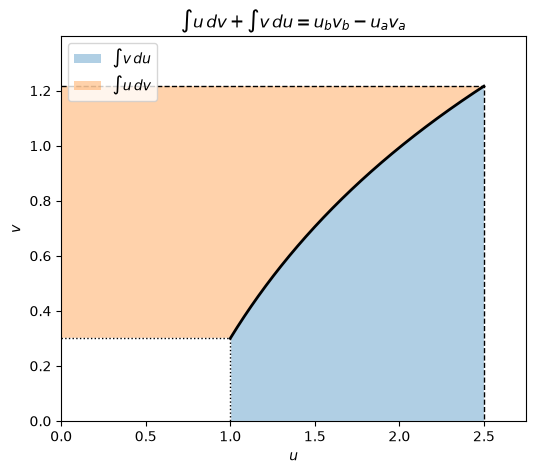

∫u dv + ∫v du = 2.740727
u_b v_b - u_a v_a = 2.740727


In [14]:
t = np.linspace(1, 2.5, 400)
u_t, v_t = t, np.log(t) + 0.3      # an example curve: u = t, v = ln t + 0.3
ua, ub, va, vb = u_t[0], u_t[-1], v_t[0], v_t[-1]

fig, ax = plt.subplots(figsize=(6, 5))
ax.fill_between(u_t, 0, v_t, alpha=0.35, label=r"$\int v\,du$")
ax.fill_betweenx(v_t, 0, u_t, alpha=0.35, label=r"$\int u\,dv$")
ax.fill_between([0, ua], 0, va, color="white")          # remove the small rectangle u_a·v_a
ax.plot(u_t, v_t, "k", lw=2)
ax.plot([0, ub, ub], [vb, vb, 0], "k--", lw=1)
ax.plot([0, ua, ua], [va, va, 0], "k:", lw=1)
ax.set_xlim(0, ub * 1.1); ax.set_ylim(0, vb * 1.15)
ax.set_xlabel("$u$"); ax.set_ylabel("$v$")
ax.set_title(r"$\int u\,dv + \int v\,du = u_b v_b - u_a v_a$")
ax.legend(loc="upper left")
plt.show()

# Numerical confirmation of the identity for this curve
int_v_du = np.trapezoid(v_t, u_t)
int_u_dv = np.trapezoid(u_t, v_t)
print(f"∫u dv + ∫v du = {int_u_dv + int_v_du:.6f}")
print(f"u_b v_b - u_a v_a = {ub * vb - ua * va:.6f}")

## 10. Common mistakes

1. **Forgetting the minus sign:** the formula is $uv\ \mathbf{-}\int v\,du$.
2. **Choosing $u$ so the integral gets harder** (Section 3: $u = \sin x$, $dv = x\,dx$).
3. **Definite integrals:** evaluate the boundary term $\big[uv\big]_a^b$, not just the remaining integral.
4. **Cyclic integrals:** if you swap the roles of $u$ and $dv$ on the second step, you undo the first step and end up with $I = I$.
5. **Not checking the answer.** Differentiate it! (`check(F, integrand)` above does this.)

## 11. Practice problems

Try each by hand first, then run the cell below to check your answers.

1. $\displaystyle\int x e^{2x}\,dx$
2. $\displaystyle\int x^2\ln x\,dx$
3. $\displaystyle\int \sin^{-1}x\,dx$
4. $\displaystyle\int e^{2x}\cos 3x\,dx$
5. $\displaystyle\int_1^e (\ln x)^2\,dx$
6. $\displaystyle\int x^4 e^{-x}\,dx$ (try the tabular method)

In [15]:
problems = [
    x * sp.exp(2 * x),
    x**2 * sp.log(x),
    sp.asin(x),
    sp.exp(2 * x) * sp.cos(3 * x),
    x**4 * sp.exp(-x),
]
for p in problems:
    F = sp.simplify(sp.integrate(p, x))
    display(Math(r"\int " + sp.latex(p) + r"\,dx = " + sp.latex(F) + " + C"))

definite = sp.integrate(sp.log(x)**2, (x, 1, sp.E))
display(Math(r"\int_1^e (\ln x)^2\,dx = " + sp.latex(sp.simplify(definite)) + rf" \approx {float(definite):.6f}"))
xs = np.linspace(1, np.e, 100_001)
print(f"NumPy check: {np.trapezoid(np.log(xs)**2, xs):.6f}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

NumPy check: 0.718282


## Summary

| Situation | Choice | Example |
|---|---|---|
| Polynomial × trig/exp | $u$ = polynomial (repeat or use the table) | $\int x^2e^x\,dx$ |
| Single log or inverse trig | $u$ = the function, $dv = dx$ | $\int\ln x\,dx$, $\int\tan^{-1}x\,dx$ |
| Polynomial × log | $u$ = log | $\int x^2\ln x\,dx$ |
| Exp × sin/cos | Parts twice, then solve for $I$ | $\int e^x\sin x\,dx$ |
| Powers $\sin^n$, $\cos^n$, $\sec^n$ | Reduction formula | $\int\sin^n x\,dx$ |

$$\int u\,dv = uv - \int v\,du$$